# Fashion-MNIST: RegNet-Y-400MF transfer learning

**Aditya · Milestone 2.2 · Team T112**
*Project 11: Inventory Image Tagging via Handcrafted Features and Deep Learning*

Hybrid-innovation experiment: an ImageNet-pretrained `torchvision` RegNet-Y-400MF is adapted to Fashion-MNIST (see `src/dl/models/regnet.py`) and compared against the from-scratch CNNs.

**Adaptation**
- Stem convolution: $3 \to 1$ input channel by averaging the pretrained RGB filters.
- Head: `Linear(440, 1000)` replaced by `Linear(440, 10)`.

**Two-stage fine-tuning**
1. **Stage 1 (head only):** backbone frozen, classification head trained for 3 epochs (Adam, $lr = 10^{-3}$).
2. **Stage 2 (full network):** every layer unfrozen, fine-tuned at $lr = 10^{-4}$ with early stopping on validation Macro F1 (patience 5, at most 30 epochs).

Same data split, augmentation, seed (42) and engine (`fit_model`) as the CNN benchmark in notebook 07, so results are directly comparable.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file() and (p / "src" / "dl").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or notebooks/ directory.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.data import CLASS_NAMES
from dl.data import get_dataloaders
from dl.models.regnet import build_regnet, count_parameters, freeze_backbone, unfreeze_all
from dl.training import evaluate_model, fit_model, make_result_record

SEED = 42
BATCH_SIZE = 128
STAGE1_EPOCHS = 3
STAGE1_LR = 1e-3
STAGE2_MAX_EPOCHS = 30
STAGE2_LR = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5
SHIRT = CLASS_NAMES.index("Shirt")

RESULTS_DIR = ROOT / "phase2_reports" / "results"
FIGURES_DIR = ROOT / "phase2_reports" / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.15.0 | device: mps


## 1. Build the model and check the adaptation

In [2]:
torch.manual_seed(SEED)
model = build_regnet(pretrained=True)

stem = model.stem[0]
print("stem conv:", stem)
print("head     :", model.fc)
with torch.no_grad():
    print("logits shape for (4, 1, 28, 28):", tuple(model(torch.randn(4, 1, 28, 28)).shape))
print(f"total parameters: {count_parameters(model, trainable_only=False):,}")

freeze_backbone(model)
print(f"trainable in stage 1 (head only): {count_parameters(model):,}")
unfreeze_all(model)
print(f"trainable in stage 2 (all)      : {count_parameters(model):,}")

stem conv: Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
head     : Linear(in_features=440, out_features=10, bias=True)
logits shape for (4, 1, 28, 28): (4, 10)
total parameters: 3,906,978
trainable in stage 1 (head only): 4,410
trainable in stage 2 (all)      : 3,906,978


## 2. Data

In [3]:
train_loader, val_loader, test_loader = get_dataloaders(
    batch_size=BATCH_SIZE, data_dir=ROOT / "data" / "raw", seed=SEED,
)
print(len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))

48000 12000 10000


## 3. Stage 1: train the head with the backbone frozen

Three epochs, no early stopping (patience exceeds the epoch budget). The frozen backbone still lets BatchNorm statistics adapt to Fashion-MNIST inputs.

In [4]:
torch.manual_seed(SEED)
model = build_regnet(pretrained=True)
freeze_backbone(model)

history1 = fit_model(
    model, train_loader, val_loader,
    epochs=STAGE1_EPOCHS, lr=STAGE1_LR, weight_decay=WEIGHT_DECAY,
    patience=PATIENCE, device=DEVICE,
)

Training on device: mps


Epoch   1/3 | Loss: 1.7405 | Train Acc: 0.3965 | Val Acc: 0.5267 | Val F1: 0.5119 | LR: 0.001000 ← best


Epoch   2/3 | Loss: 1.5200 | Train Acc: 0.4757 | Val Acc: 0.5231 | Val F1: 0.5089 | LR: 0.001000


Epoch   3/3 | Loss: 1.5040 | Train Acc: 0.4815 | Val Acc: 0.5351 | Val F1: 0.5239 | LR: 0.001000 ← best

Training complete. Best Val Macro F1: 0.5239 at epoch 3. Total time: 35.2s


## 4. Stage 2: unfreeze everything and fine-tune at $lr = 10^{-4}$

Early stopping on validation Macro F1 (patience 5); the best-epoch weights are restored.

In [5]:
unfreeze_all(model)
print(f"trainable parameters: {count_parameters(model):,}")

history2 = fit_model(
    model, train_loader, val_loader,
    epochs=STAGE2_MAX_EPOCHS, lr=STAGE2_LR, weight_decay=WEIGHT_DECAY,
    patience=PATIENCE, device=DEVICE,
)

trainable parameters: 3,906,978
Training on device: mps


Epoch   1/30 | Loss: 1.1731 | Train Acc: 0.5908 | Val Acc: 0.6984 | Val F1: 0.6901 | LR: 0.000100 ← best


Epoch   2/30 | Loss: 0.8046 | Train Acc: 0.7108 | Val Acc: 0.7690 | Val F1: 0.7609 | LR: 0.000100 ← best


Epoch   3/30 | Loss: 0.6713 | Train Acc: 0.7551 | Val Acc: 0.7920 | Val F1: 0.7843 | LR: 0.000100 ← best


Epoch   4/30 | Loss: 0.5930 | Train Acc: 0.7798 | Val Acc: 0.8204 | Val F1: 0.8160 | LR: 0.000100 ← best


Epoch   5/30 | Loss: 0.5293 | Train Acc: 0.8062 | Val Acc: 0.8382 | Val F1: 0.8351 | LR: 0.000100 ← best


... (21 outputs left out)

Epoch  27/30 | Loss: 0.1831 | Train Acc: 0.9305 | Val Acc: 0.9207 | Val F1: 0.9204 | LR: 0.000100 ← best


Epoch  28/30 | Loss: 0.1736 | Train Acc: 0.9339 | Val Acc: 0.9205 | Val F1: 0.9203 | LR: 0.000100


Epoch  29/30 | Loss: 0.1677 | Train Acc: 0.9361 | Val Acc: 0.9224 | Val F1: 0.9222 | LR: 0.000100 ← best


Epoch  30/30 | Loss: 0.1587 | Train Acc: 0.9401 | Val Acc: 0.9194 | Val F1: 0.9190 | LR: 0.000100

Training complete. Best Val Macro F1: 0.9222 at epoch 29. Total time: 992.2s


## 5. Training curves

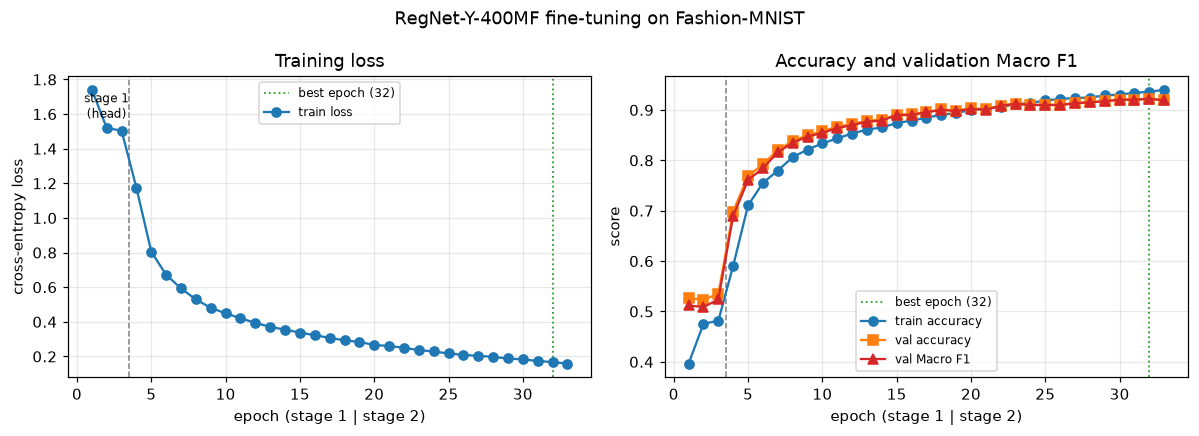

In [6]:
s1 = len(history1["train_loss"])
epochs = np.arange(1, s1 + len(history2["train_loss"]) + 1)
train_loss = history1["train_loss"] + history2["train_loss"]
train_acc = history1["train_accuracy"] + history2["train_accuracy"]
val_acc = history1["val_accuracy"] + history2["val_accuracy"]
val_f1 = history1["val_macro_f1"] + history2["val_macro_f1"]
best_global = s1 + history2["best_epoch"] + 1

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax in axes:
    ax.axvline(s1 + 0.5, color="gray", ls="--", lw=1)
    ax.axvline(best_global, color="tab:green", ls=":", lw=1.2, label=f"best epoch ({best_global})")

axes[0].plot(epochs, train_loss, "o-", color="tab:blue", label="train loss")
axes[0].set_ylabel("cross-entropy loss")
axes[0].set_title("Training loss")
axes[0].text(s1 / 2 + 0.5, axes[0].get_ylim()[1] * 0.95, "stage 1\n(head)", ha="center", va="top", fontsize=8)

axes[1].plot(epochs, train_acc, "o-", color="tab:blue", label="train accuracy")
axes[1].plot(epochs, val_acc, "s-", color="tab:orange", label="val accuracy")
axes[1].plot(epochs, val_f1, "^-", color="tab:red", label="val Macro F1")
axes[1].set_ylabel("score")
axes[1].set_title("Accuracy and validation Macro F1")

for ax in axes:
    ax.set_xlabel("epoch (stage 1 | stage 2)")
    ax.legend(loc="best", fontsize=8)
fig.suptitle("RegNet-Y-400MF fine-tuning on Fashion-MNIST")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "regnet_finetuning_curves.png", bbox_inches="tight")
plt.show()

## 6. Held-out test evaluation and export

In [7]:
import time

def measure_latency_ms(model, loader, device, n_iterations=5):
    model.eval()
    batches = [images.to(device) for images, _ in loader]
    n_images = sum(len(b) for b in batches)

    def run():
        with torch.no_grad():
            for batch in batches:
                model(batch).argmax(dim=1).cpu()

    run()
    times = []
    for _ in range(n_iterations):
        start = time.perf_counter()
        run()
        times.append((time.perf_counter() - start) / n_images)
    return float(np.median(times) * 1000.0)

test_metrics = evaluate_model(model, test_loader, DEVICE)

total_seconds = history1["total_seconds"] + history2["total_seconds"]
combined = {
    "best_epoch": s1 + history2["best_epoch"],  # 0-based, over both stages
    "best_val_macro_f1": history2["best_val_macro_f1"],
    "stopped_early": history2["stopped_early"],
    "total_seconds": total_seconds,
}
record = make_result_record(
    model_name="regnet_finetuned",
    test_metrics=test_metrics,
    history=combined,
    best_params={
        "architecture": "regnet_y_400mf (ImageNet1K_V2, 1-channel stem, Linear(440, 10))",
        "optimizer": "Adam",
        "stage1": {"trainable": "head only", "epochs": s1, "lr": STAGE1_LR},
        "stage2": {
            "trainable": "all", "lr": STAGE2_LR, "max_epochs": STAGE2_MAX_EPOCHS,
            "epochs_trained": len(history2["train_loss"]),
            "early_stopping_patience": PATIENCE,
        },
        "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "epochs_trained": s1 + len(history2["train_loss"]),
        "augmentation": "RandomHorizontalFlip(0.5) + RandomRotation(10)",
        "seed": SEED,
        "device": str(DEVICE),
    },
    train_n=len(train_loader.dataset),
    val_n=len(val_loader.dataset),
    test_n=len(test_loader.dataset),
    inference_latency_ms=measure_latency_ms(model, test_loader, DEVICE),
    parameter_count=count_parameters(model, trainable_only=False),
)
record["history"] = {
    "train_loss": train_loss, "train_accuracy": train_acc,
    "val_accuracy": val_acc, "val_macro_f1": val_f1,
    "stage1_epochs": s1,
}

with open(RESULTS_DIR / "regnet_finetuned.json", "w") as f:
    json.dump(record, f, indent=2)

print(f"test accuracy : {record['test_accuracy']:.4f}")
print(f"test Macro F1 : {record['test_macro_f1']:.4f}")
print(f"Shirt recall  : {record['per_class_recall'][SHIRT]:.4f}")
print(f"parameters    : {record['parameter_count']:,}")
print(f"latency       : {record['inference_latency_ms_per_image']:.4f} ms/image")

test accuracy : 0.9146
test Macro F1 : 0.9142
Shirt recall  : 0.7340
parameters    : 3,906,978
latency       : 0.1207 ms/image


## 7. Comparison with the from-scratch CNNs

In [8]:
import pandas as pd

rows = []
for name in ("cnn_simple", "cnn_deep", "regnet_finetuned"):
    path = RESULTS_DIR / f"{name}.json"
    if not path.exists():
        continue
    r = json.load(open(path))
    rows.append({
        "model": name,
        "test accuracy": r["test_accuracy"],
        "test Macro F1": r["test_macro_f1"],
        "Shirt recall": r["per_class_recall"][SHIRT],
        "parameters": r["parameter_count"],
        "train time (s)": r["total_training_seconds"],
    })
pd.DataFrame(rows).round(4).set_index("model")

,test accuracy,test Macro F1,Shirt recall,parameters,train time (s)
model,,,,,
cnn_simple,0.9114,0.9108,0.709,421738,238.6641
cnn_deep,0.9221,0.9216,0.732,390634,258.0422
regnet_finetuned,0.9146,0.9142,0.734,3906978,1027.3653


In [9]:
recall = pd.Series(record["per_class_recall"], index=CLASS_NAMES, name="recall").round(3)
recall.to_frame().T

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
recall,0.864,0.977,0.885,0.922,0.864,0.969,0.734,0.979,0.991,0.961
